# Handwritten Character Recognition

## CodeAlpha Machine Learning Internship — Task 3

This project uses a Convolutional Neural Network (CNN) to recognize handwritten digits from the MNIST dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.datasets import mnist

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 1. Load the MNIST Dataset

In this step, we will load the MNIST dataset and inspect the shapes of the training and testing images and labels.

In [2]:
# Load the dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


## 2. Visualize Sample Images

In this step, we will display sample handwritten digits and their corresponding labels.

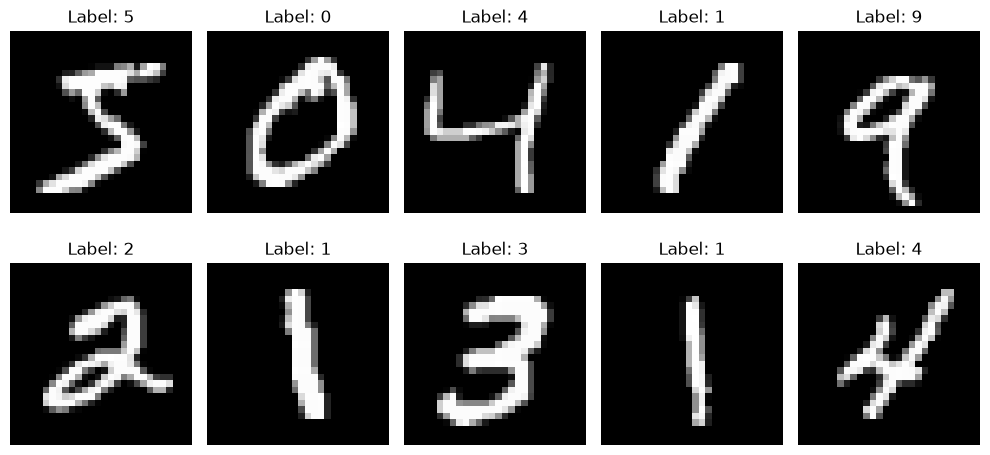

In [3]:
# Display sample images
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 3. Analyze Digit Distribution

In this step, we will count the number of training images for each digit from 0 to 9.

0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


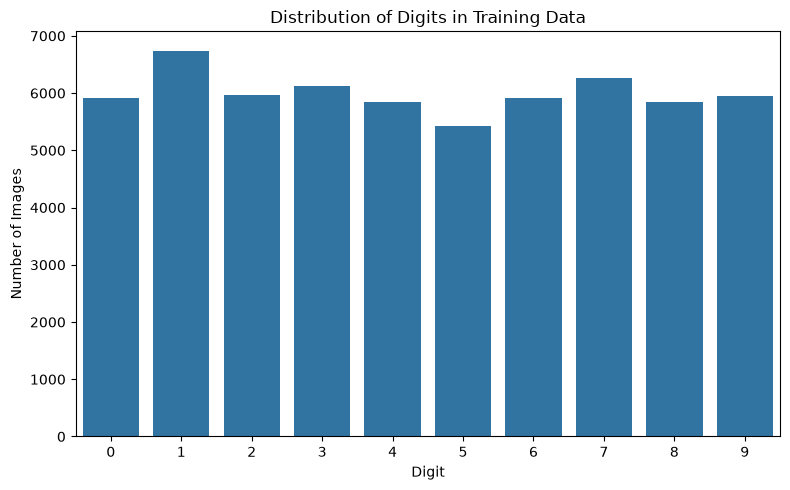

In [4]:
# Count images for each digit
digit_counts = pd.Series(y_train).value_counts().sort_index()

print(digit_counts)

# Plot digit distribution
plt.figure(figsize=(8, 5))
sns.countplot(x=y_train)

plt.title("Distribution of Digits in Training Data")
plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

## 4. Normalize and Reshape Images

In this step, we will normalize pixel values from 0–255 to 0–1 and reshape the images into the format required by a CNN.

In [5]:
# Normalize pixel values
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add channel dimension
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nMinimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)

Minimum pixel value: 0.0
Maximum pixel value: 1.0


## 5. Build the CNN Model

In this step, we will create a Convolutional Neural Network (CNN) to recognize handwritten digits using convolution, pooling, and dense layers.

In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

# Build the CNN
cnn_model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(10, activation="softmax")
])

# Compile the model
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the CNN Model

In this step, we will train the CNN using the training images and validate its performance on a portion of the training data.

In [7]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = cnn_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.10,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 252s 585ms/step - accuracy: 0.9240 - loss: 0.2517 - val_accuracy: 0.9827 - val_loss: 0.0569
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 210s 462ms/step - accuracy: 0.9780 - loss: 0.0738 - val_accuracy: 0.9868 - val_loss: 0.0484
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 208s 477ms/step - accuracy: 0.9836 - loss: 0.0530 - val_accuracy: 0.9863 - val_loss: 0.0457
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 295s 698ms/step - accuracy: 0.9879 - loss: 0.0404 - val_accuracy: 0.9892 - val_loss: 0.0396
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 290s 622ms/step - accuracy: 0.9895 - loss: 0.0339 - val_accuracy: 0.9897 - val_loss: 0.0384
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 306s 584ms/step - accuracy: 0.9908 - loss: 0.0288 - val_accuracy: 0.9907 - val_loss: 0.0365
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 249s 554ms/step - accuracy: 0.9920 - loss: 0.0253 - val_accuracy: 0.9905 - val_loss: 0.0320
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 240s 501ms/step - accuracy: 0.9935 -

## 7. Evaluate the CNN Model

In this step, we will evaluate the trained CNN on the 10,000 test images to measure its performance on unseen data.

In [8]:
test_loss, test_accuracy = cnn_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step - accuracy: 0.9921 - loss: 0.0250
Test Loss: 0.0250
Test Accuracy: 0.9921
Test Accuracy (%): 99.21%


## 8. Classification Report

In this step, we will calculate precision, recall, and F1-score for each digit from 0 to 9.

In [9]:
from sklearn.metrics import classification_report

# Predict digit probabilities
y_pred_probs = cnn_model.predict(X_test, verbose=0)

# Convert probabilities to predicted digits
y_pred = np.argmax(y_pred_probs, axis=1)

# Display classification report
print(classification_report(
    y_test,
    y_pred,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9969    0.9939    0.9954       980
           1     0.9947    0.9947    0.9947      1135
           2     0.9961    0.9884    0.9922      1032
           3     0.9940    0.9921    0.9931      1010
           4     0.9969    0.9959    0.9964       982
           5     0.9823    0.9944    0.9883       892
           6     0.9968    0.9875    0.9921       958
           7     0.9827    0.9932    0.9879      1028
           8     0.9877    0.9918    0.9898       974
           9     0.9920    0.9891    0.9906      1009

    accuracy                         0.9921     10000
   macro avg     0.9920    0.9921    0.9920     10000
weighted avg     0.9921    0.9921    0.9921     10000



## 9. Confusion Matrix

In this step, we will visualize the confusion matrix to identify correct predictions and misclassifications for each digit.

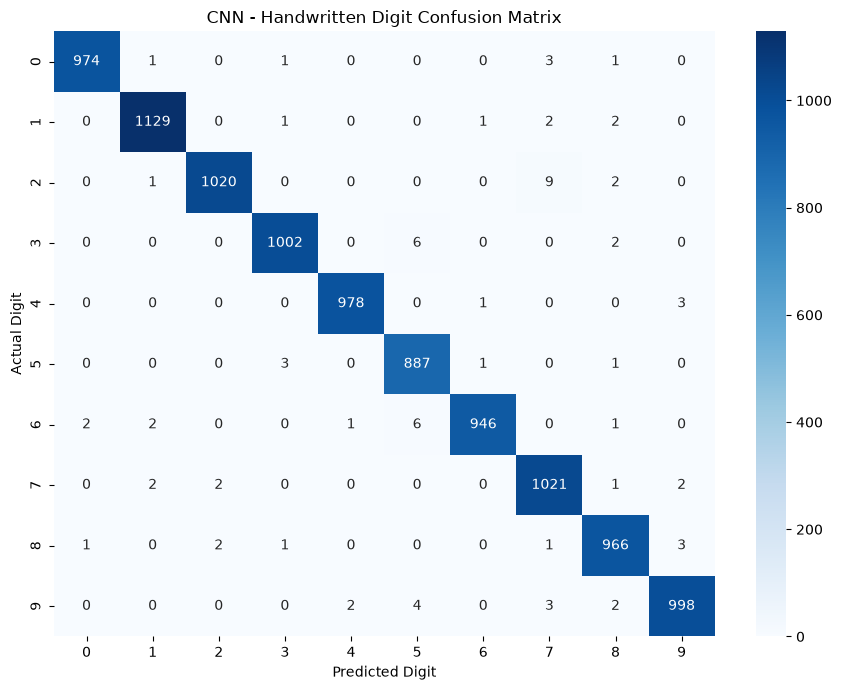

In [10]:
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("CNN - Handwritten Digit Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.tight_layout()
plt.show()

## 10. Training and Validation Curves

These plots compare training and validation accuracy and loss across epochs to evaluate model learning and generalization.

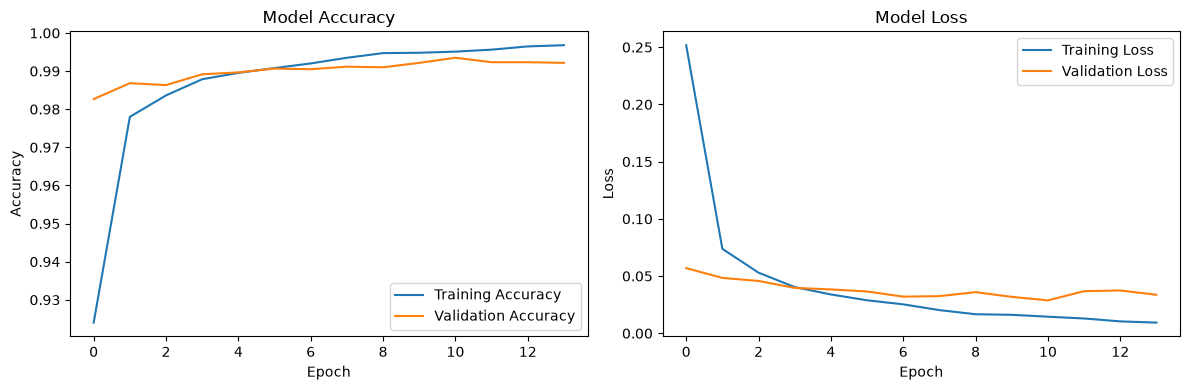

In [11]:
plt.figure(figsize=(12, 4))

# Accuracy curves
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss curves
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 11. Sample Predictions

This step compares the CNN's predicted digits with the actual labels for sample test images.

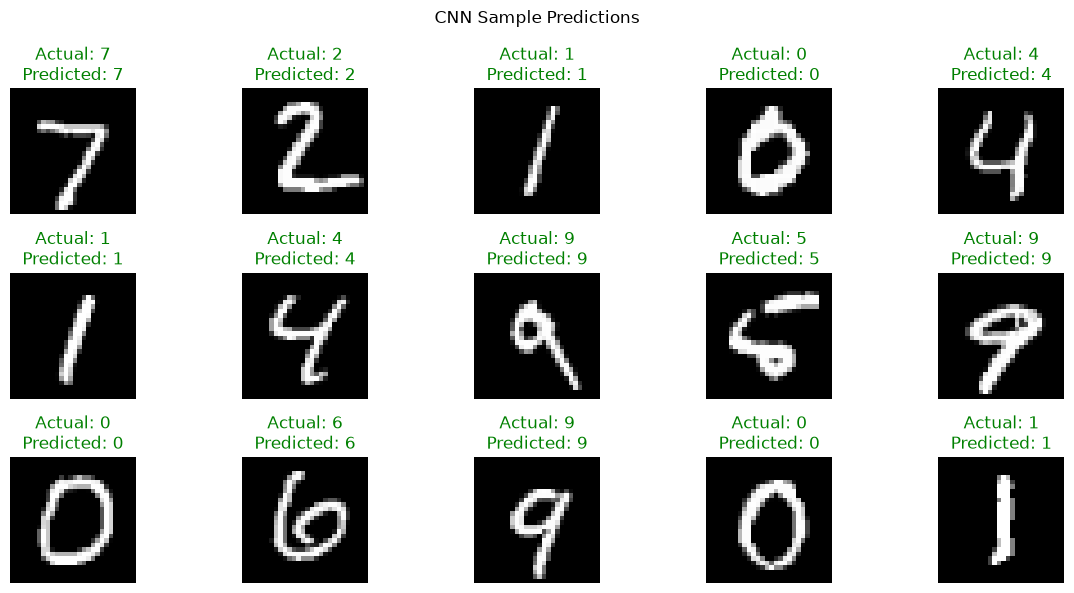

In [12]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[i].squeeze(), cmap="gray")

    actual = y_test[i]
    predicted = y_pred[i]

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color
    )
    plt.axis("off")

plt.suptitle("CNN Sample Predictions")
plt.tight_layout()
plt.show()

## 12. Save the Trained Model

Save the trained CNN so it can be reused for future handwritten digit predictions without retraining.

In [13]:
import os

os.makedirs("../models", exist_ok=True)

model_path = "../models/handwritten_digit_cnn.keras"
cnn_model.save(model_path)

print("Model saved successfully:", model_path)

Model saved successfully: ../models/handwritten_digit_cnn.keras


In [14]:
print("Model available:", "cnn_model" in globals())

Model available: True


In [15]:
from pathlib import Path

model_dir = Path.cwd().parent / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "handwritten_digit_cnn.keras"

cnn_model.save(model_path)

print("Saved to:", model_path.resolve())
print("File exists:", model_path.exists())
print("File size (MB):", round(model_path.stat().st_size / (1024 ** 2), 2))

Saved to: D:\CodeAlpha_machine_learning\Task_3_Handwritten_Character_Recognition\models\handwritten_digit_cnn.keras
File exists: True
File size (MB): 2.61
